# Кластеризация ЕГЭ — выполненное домашнее задание

Решение двух частей: ручная кластеризация таблиц, поиск медоидов и сравнение
MiniBatchKMeans с DBSCAN. Все ячейки выполняются последовательно сверху вниз.
Данные лежат рядом с ноутбуком; результаты сохраняются в `results/`.

## 1. Задание

Рядом лежат экселевские таблицы с координатами точек. В 3 и 4 задаче используется манхетеское расстояние. В остальных Евклидово.

* Постройте Распределение точек
* Кластеризуйте руками
* Постройте Распределение точек, отметьте принадлежность кластеров цветами
* Найдите среди в каждом кластере точку расстояние от которой до всех остальных минимально
* Выведите усреднение центров всех кластеров * 1000

### Как трактуется условие

Файлы названы от `0` до `5`. Под «3 и 4 задачей» далее понимаются **третья
и четвёртая таблицы**, то есть `2.xlsx` и `3.xlsx`: для них используем
манхэттенское расстояние. Для остальных — евклидово. Ниже также приведён
полный пересчёт для трактовки «файлы с номерами 3 и 4», чтобы неоднозначность
нумерации не скрывалась.

Искомый центр — **медоид**: точка самого кластера, минимизирующая сумму
расстояний до всех его точек. Среднее арифметическое координат точек кластера
не обязано быть медоидом. В итоговом ответе усредняем координаты медоидов
с одинаковым весом для каждого кластера, затем умножаем на 1000.

In [1]:
from pathlib import Path
import os
import time

os.environ.setdefault("MPLCONFIGDIR", "/tmp/cluster_ege-mpl")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.spatial.distance import cdist
from sklearn import cluster, datasets
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score
from threadpoolctl import threadpool_limits

# Ограничиваем число потоков, чтобы сравнение не зависело от числа ядер машины.
thread_limit = threadpool_limits(limits=1)
pd.set_option("display.precision", 6)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
DATA_DIR = Path.cwd() if (Path.cwd() / "0.xls").exists() else Path.cwd() / "EGE"
if not (DATA_DIR / "0.xls").exists():
    raise FileNotFoundError("Запустите ноутбук из папки EGE или её родительской папки")
RESULTS_DIR = DATA_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)
FILENAMES = ["0.xls", "1.xls", "2.xlsx", "3.xlsx", "4.xlsx", "5.xlsx"]
PALETTE = ["#377eb8", "#ff7f00", "#4daf4a"]

### Загрузка и проверка данных

В файлах `0.xls`, `1.xls`, `4.xlsx`, `5.xlsx` есть заголовки `X`, `Y`,
а `2.xlsx` и `3.xlsx` начинаются сразу с чисел. Читаем с `header=None`
и удаляем только распознанный заголовок, сохраняя первую точку файлов без заголовка.

In [2]:
def load_points(path):
    frame = pd.read_excel(path, header=None)
    assert frame.shape[1] == 2, f"Ожидались два столбца: {path.name}"
    if [str(value).strip().upper() for value in frame.iloc[0]] == ["X", "Y"]:
        frame = frame.iloc[1:]
    points = frame.apply(pd.to_numeric, errors="raise").to_numpy(dtype=float)
    assert len(points) and np.isfinite(points).all(), f"Некорректные точки: {path.name}"
    return points

ege_points = {name: load_points(DATA_DIR / name) for name in FILENAMES}
expected_counts = [100, 9999, 1000, 10000, 500, 9999]
assert [len(ege_points[name]) for name in FILENAMES] == expected_counts
display(pd.DataFrame([
    {"Файл": name, "Количество точек": len(points),
     "min X": points[:, 0].min(), "max X": points[:, 0].max(),
     "min Y": points[:, 1].min(), "max Y": points[:, 1].max()}
    for name, points in ege_points.items()
]))

,Файл,Количество точек,min X,max X,min Y,max Y
0,0.xls,100,-0.744189,2.875678,4.330163,9.205245
1,1.xls,9999,5.120260,11.075804,-2.569932,3.533126
2,2.xlsx,1000,2.538641,44.721699,-9.638561,11.101653
3,3.xlsx,10000,-35.307610,40.739806,-19.420296,9.649734
4,4.xlsx,500,-2.802751,6.822937,-0.080601,9.749908
5,5.xlsx,9999,-6.623701,6.603804,-2.360397,9.175577


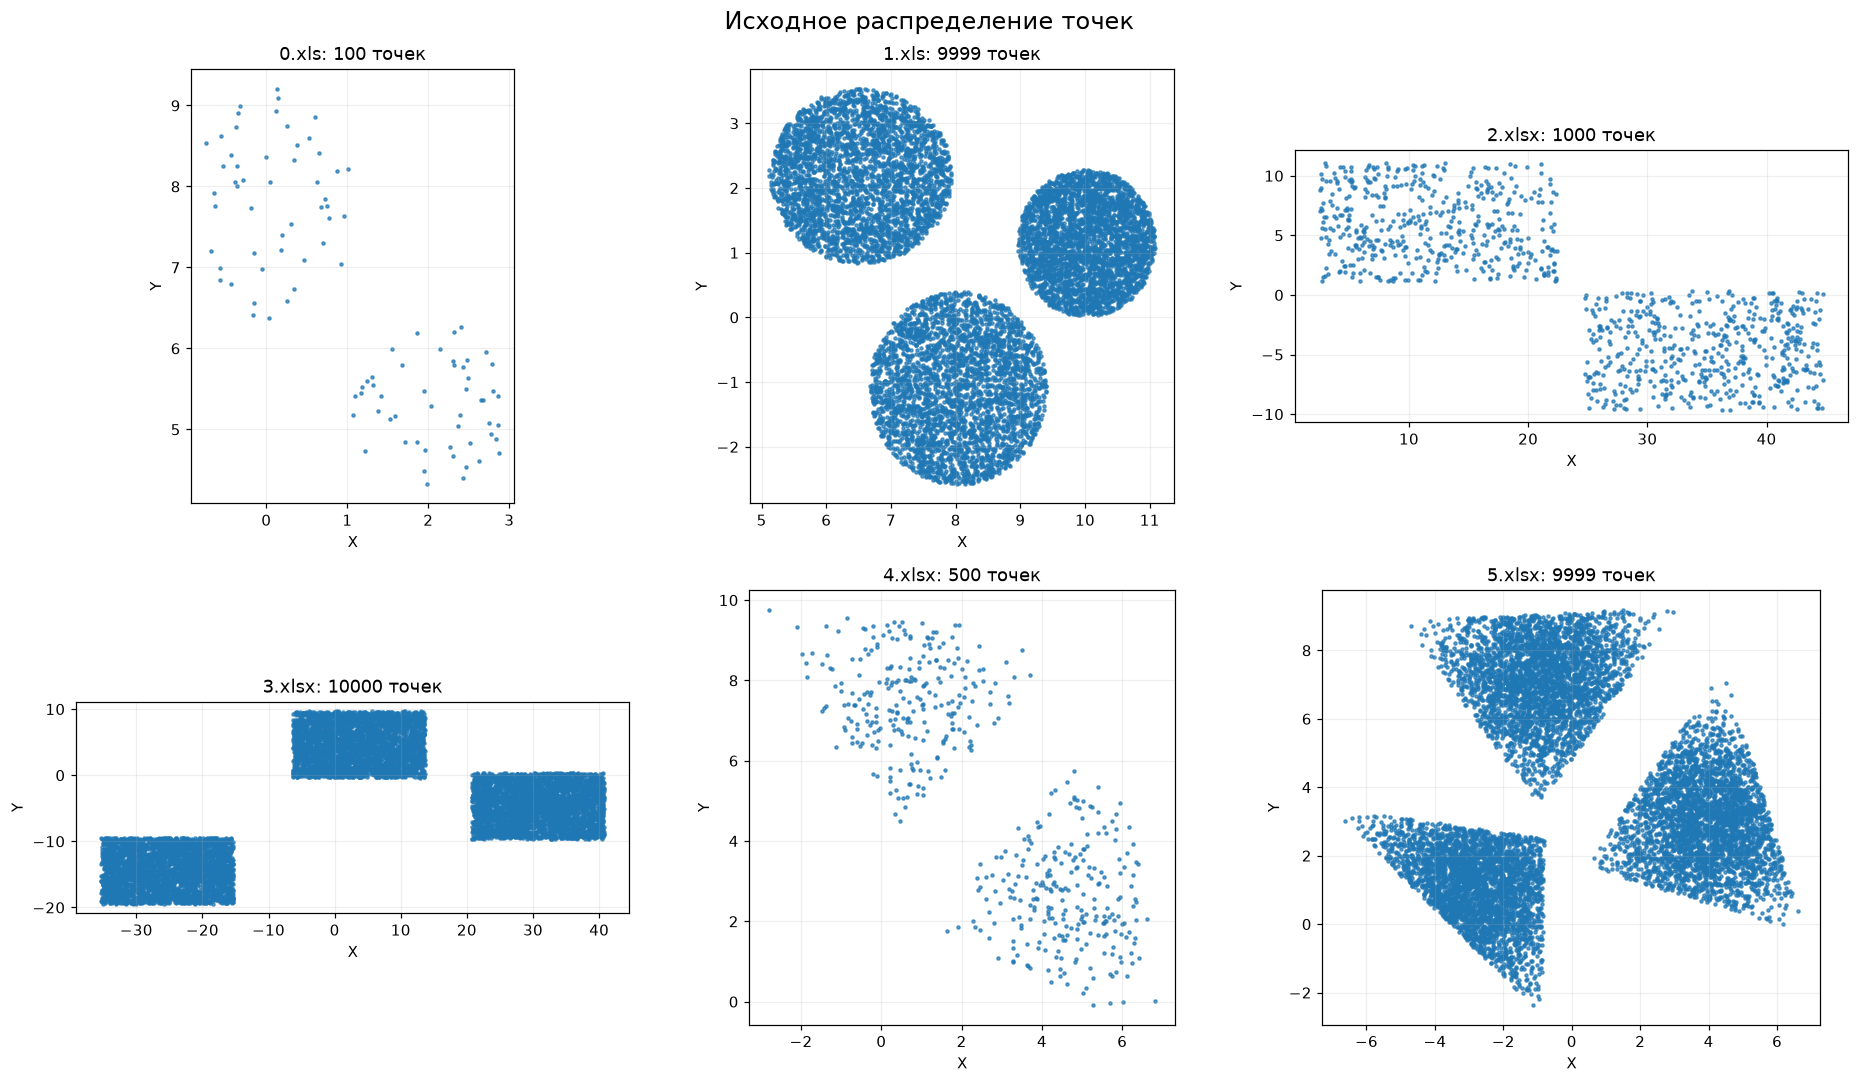

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for ax, (name, points) in zip(axes.flat, ege_points.items()):
    ax.scatter(points[:, 0], points[:, 1], s=4, alpha=0.7)
    ax.set(title=f"{name}: {len(points)} точек", xlabel="X", ylabel="Y")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.2)
fig.suptitle("Исходное распределение точек", fontsize=16)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "ege_raw.png", dpi=160, bbox_inches="tight")
plt.show()

### Ручная кластеризация

На графиках видны 2, 3, 2, 3, 2 и 3 группы соответственно. По промежуткам
между ними вручную выбраны следующие границы. Алгоритмы обучения для этой
части не используются; каждая точка получает метку по явному условию.

| Файл | Правила присвоения метки |
| --- | --- |
| `0.xls` | 0: `y > x + 5`; иначе 1 |
| `1.xls` | 0: `y > x - 6.7`; среди оставшихся 1: `x + y < 9.3`; иначе 2 |
| `2.xlsx` | 0: `x < 23.5`; иначе 1 |
| `3.xlsx` | 0: `x < -10`; 1: `-10 ≤ x < 17`; иначе 2 |
| `4.xlsx` | 0: `y > x + 2.5`; иначе 1 |
| `5.xlsx` | 0: `x + y < 2`; среди оставшихся 1: `y > x + 3.7`; иначе 2 |

Границы проходят по пустым промежуткам; метки обозначают группы, а не их качество.

In [4]:
def manual_labels(name, points):
    x, y = points.T
    if name == "0.xls":
        return np.where(y > x + 5, 0, 1)
    if name == "1.xls":
        return np.where(y > x - 6.7, 0, np.where(x + y < 9.3, 1, 2))
    if name == "2.xlsx":
        return np.where(x < 23.5, 0, 1)
    if name == "3.xlsx":
        return np.where(x < -10, 0, np.where(x < 17, 1, 2))
    if name == "4.xlsx":
        return np.where(y > x + 2.5, 0, 1)
    if name == "5.xlsx":
        return np.where(x + y < 2, 0, np.where(y > x + 3.7, 1, 2))
    raise ValueError(name)

ege_labels = {name: manual_labels(name, points) for name, points in ege_points.items()}
cluster_sizes = pd.DataFrame([
    {"Файл": name, "Кластер": int(label), "Точек": int(np.sum(labels == label))}
    for name, labels in ege_labels.items() for label in np.unique(labels)
])
assert cluster_sizes.groupby("Файл")["Точек"].sum().to_dict() == {
    name: len(points) for name, points in ege_points.items()
}
display(cluster_sizes)

,Файл,Кластер,Точек
0,0.xls,0,50
1,0.xls,1,50
2,1.xls,0,3333
3,1.xls,1,3333
4,1.xls,2,3333
5,2.xlsx,0,476
6,2.xlsx,1,524
7,3.xlsx,0,3429
8,3.xlsx,1,3284
9,3.xlsx,2,3287


### Поиск медоидов и вычисление ответа

Для каждого кластера $C$ перебираем все его точки:

$$m_C = \underset{p\in C}{\operatorname{argmin}}\ \sum_{q\in C} d(p,q).$$

Евклидово расстояние: $d(p,q)=\sqrt{(p_x-q_x)^2+(p_y-q_y)^2}$,
манхэттенское: $d(p,q)=|p_x-q_x|+|p_y-q_y|$.
Расстояние до самой точки равно нулю и на минимум не влияет.
Считаем суммы блоками, чтобы не хранить всю квадратную матрицу расстояний.
Это точный перебор, без аппроксимации; при равенстве выбирается первая точка.

При $k$ кластерах итог: $1000\cdot\frac{1}{k}\sum_{j=1}^{k}m_{C_j}$.

In [5]:
def find_medoid(points, metric, block_size=256):
    sums = np.empty(len(points), dtype=float)
    for start in range(0, len(points), block_size):
        stop = min(start + block_size, len(points))
        sums[start:stop] = cdist(points[start:stop], points, metric=metric).sum(axis=1)
    index = int(np.argmin(sums))
    return index, points[index].copy(), float(sums[index])

# Оба расстояния нужны также для проверки неоднозначной нумерации задач.
medoid_cache = {}
for name, points in ege_points.items():
    labels = ege_labels[name]
    for label in np.unique(labels):
        member_indices = np.flatnonzero(labels == label)
        members = points[member_indices]
        for metric in ["euclidean", "cityblock"]:
            index, center, distance_sum = find_medoid(members, metric)
            global_index = int(member_indices[index])
            assert np.array_equal(center, points[global_index])
            medoid_cache[name, int(label), metric] = {
                "center": center, "sum": distance_sum,
                "point_index": global_index, "size": len(members)
            }

MANHATTAN_FILES = {"2.xlsx", "3.xlsx"}
def result_tables(manhattan_files):
    center_rows, answer_rows = [], []
    for name in FILENAMES:
        metric = "cityblock" if name in manhattan_files else "euclidean"
        centers = []
        for label in np.unique(ege_labels[name]):
            result = medoid_cache[name, int(label), metric]
            x, y = result["center"]
            centers.append([x, y])
            center_rows.append({
                "Файл": name, "Кластер": int(label), "Метрика": metric,
                "Точек": result["size"], "Индекс точки (с 0)": result["point_index"],
                "Центр X": x, "Центр Y": y, "Сумма расстояний": result["sum"]
            })
        mean_x, mean_y = np.mean(centers, axis=0) * 1000
        answer_rows.append({"Файл": name, "Метрика": metric,
                            "1000 × среднее X": mean_x, "1000 × среднее Y": mean_y})
    return pd.DataFrame(center_rows), pd.DataFrame(answer_rows)

centers_table, answers_table = result_tables(MANHATTAN_FILES)
display(centers_table)
display(answers_table)
centers_table.to_csv(RESULTS_DIR / "ege_medoids.csv", index=False)
answers_table.to_csv(RESULTS_DIR / "ege_answers.csv", index=False)
cluster_sizes.to_csv(RESULTS_DIR / "ege_cluster_sizes.csv", index=False)

,Файл,Кластер,Метрика,Точек,Индекс точки (с 0),Центр X,Центр Y,Сумма расстояний
0,0.xls,0,euclidean,50,4,0.048112,8.053051,43.298773
1,0.xls,1,euclidean,50,90,2.033901,5.289296,36.153440
2,1.xls,0,euclidean,3333,4415,6.469983,2.169761,3086.316800
3,1.xls,1,euclidean,3333,1915,8.040075,-1.108706,3177.159067
4,1.xls,2,euclidean,3333,2086,10.022535,1.154201,2456.775751
5,2.xlsx,0,cityblock,476,890,11.503607,5.559190,3548.924045
6,2.xlsx,1,cityblock,524,241,35.516199,-4.449825,3915.523772
7,3.xlsx,0,cityblock,3429,585,-25.130758,-14.413328,25631.373198
8,3.xlsx,1,cityblock,3284,5017,3.517911,4.653696,24396.131988
9,3.xlsx,2,cityblock,3287,5585,30.849529,-4.517203,24365.735516


,Файл,Метрика,1000 × среднее X,1000 × среднее Y
0,0.xls,euclidean,1041.006278,6671.173407
1,1.xls,euclidean,8177.530805,738.418676
2,2.xlsx,cityblock,23509.902668,554.682282
3,3.xlsx,cityblock,3078.894014,-4758.945238
4,4.xlsx,euclidean,2588.539922,4996.567503
5,5.xlsx,euclidean,61.652189,3723.362146


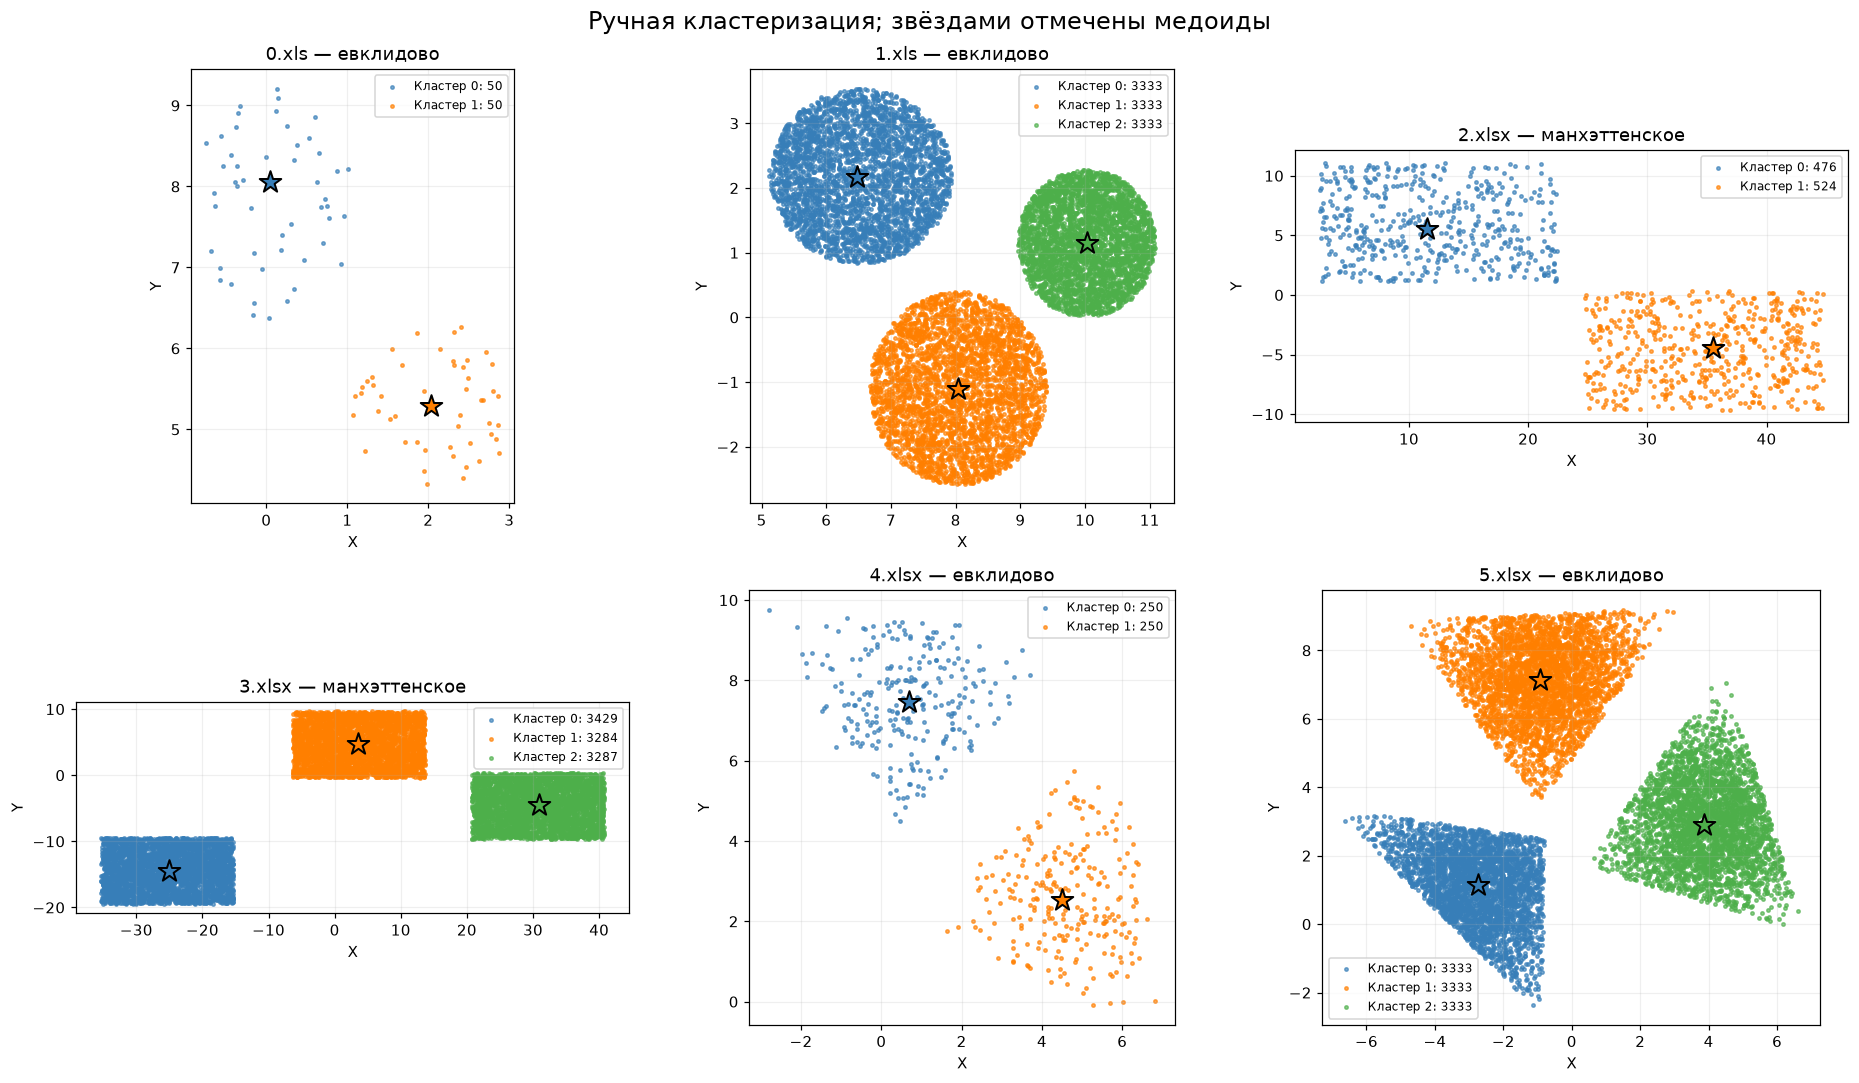

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for ax, (name, points) in zip(axes.flat, ege_points.items()):
    labels = ege_labels[name]
    metric = "cityblock" if name in MANHATTAN_FILES else "euclidean"
    for label in np.unique(labels):
        members = points[labels == label]
        ax.scatter(members[:, 0], members[:, 1], s=5, alpha=0.65,
                   color=PALETTE[label], label=f"Кластер {label}: {len(members)}")
        center = medoid_cache[name, int(label), metric]["center"]
        ax.scatter(*center, s=220, marker="*", color=PALETTE[label],
                   edgecolor="black", linewidth=1.3, zorder=5)
    metric_name = "манхэттенское" if metric == "cityblock" else "евклидово"
    ax.set(title=f"{name} — {metric_name}", xlabel="X", ylabel="Y")
    ax.set_aspect("equal", adjustable="box")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
fig.suptitle("Ручная кластеризация; звёздами отмечены медоиды", fontsize=16)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "ege_clusters.png", dpi=160, bbox_inches="tight")
plt.show()

### Проверка второй трактовки нумерации

Если «3 и 4» означает названия файлов `3.xlsx`, `4.xlsx`, меняется метрика
только в `2.xlsx` и `4.xlsx`. Ниже — ответы для всех файлов в этой трактовке.
Разбиения на кластеры сохраняются. Основной ответ выше дан без округления
до целого: условие требует умножение на 1000 и не указывает усечение.

In [7]:
alternative_centers, alternative_answers = result_tables({"3.xlsx", "4.xlsx"})
display(alternative_answers)
alternative_centers.to_csv(RESULTS_DIR / "ege_medoids_by_file_number.csv", index=False)
alternative_answers.to_csv(RESULTS_DIR / "ege_answers_by_file_number.csv", index=False)

,Файл,Метрика,1000 × среднее X,1000 × среднее Y
0,0.xls,euclidean,1041.006278,6671.173407
1,1.xls,euclidean,8177.530805,738.418676
2,2.xlsx,euclidean,23130.215759,635.342294
3,3.xlsx,cityblock,3078.894014,-4758.945238
4,4.xlsx,cityblock,2588.539922,4996.567503
5,5.xlsx,euclidean,61.652189,3723.362146


## 2. Сравнение алгоритмов кластеризации

На предложенных распределениях данных проверьте предложенные алгоритмы. Постройте графики кластеризации для каждой пары алгоритм-данные, разные кластеры покрасьте разным цветом. Воспользуйтесь sklearn реализациями. Параметры кластеризации для разных алгоритмов подберите такие, чтобы алгоритмы можно было сравнивать (по возможности одинаковое количество кластеров и т.д.)

Используем обе реализации из шаблона: `MiniBatchKMeans` и `DBSCAN`.
На кольцах и полумесяцах задаём KMeans два кластера, на трёх наборах с облаками —
три. Параметры DBSCAN выбираем отдельно по геометрии распределения так,
чтобы он выделял сопоставимое число групп. Для случайного облака оставляем
базовые параметры: данных об истинных кластерах здесь нет, и требовать от
DBSCAN ровно три группы было бы произвольно.

Каждый набор стандартизируется **один раз** до запуска обоих алгоритмов.
Метки генератора не передаются в `fit_predict`; они используются только
для последующего измерения ARI (1 — точное совпадение разбиений,
около 0 — совпадение на уровне случайности). ARI учитывает все точки,
в том числе шум DBSCAN. Время измеряется для одного запуска и служит ориентиром.

In [8]:
n_samples = 1500
noisy_circles = datasets.make_circles(
    n_samples=n_samples, factor=0.5, noise=0.05, random_state=0)
noisy_moons = datasets.make_moons(n_samples=n_samples, noise=0.05, random_state=0)
blobs = datasets.make_blobs(n_samples=n_samples, random_state=8)
no_structure = (np.random.RandomState(0).rand(n_samples, 2), None)
X_aniso, y_aniso = datasets.make_blobs(n_samples=n_samples, random_state=170)
aniso = (X_aniso @ np.array([[0.6, -0.6], [-0.4, 0.8]]), y_aniso)
varied = datasets.make_blobs(
    n_samples=n_samples, cluster_std=[1.0, 2.5, 0.5], random_state=170)

benchmark_cases = [
    ("Кольца", noisy_circles, {"n_clusters": 2, "eps": 0.30, "min_samples": 20}),
    ("Полумесяцы", noisy_moons, {"n_clusters": 2, "eps": 0.30, "min_samples": 20}),
    ("Разная дисперсия", varied, {"n_clusters": 3, "eps": 0.24, "min_samples": 15}),
    ("Вытянутые облака", aniso, {"n_clusters": 3, "eps": 0.15, "min_samples": 20}),
    ("Компактные облака", blobs, {"n_clusters": 3, "eps": 0.30, "min_samples": 20}),
    ("Случайное облако", no_structure, {"n_clusters": 3, "eps": 0.30, "min_samples": 20}),
]
display(pd.DataFrame([{"Набор": name, **params}
                      for name, _, params in benchmark_cases]))

,Набор,n_clusters,eps,min_samples
0,Кольца,2,0.30,20
1,Полумесяцы,2,0.30,20
2,Разная дисперсия,3,0.24,15
3,Вытянутые облака,3,0.15,20
4,Компактные облака,3,0.30,20
5,Случайное облако,3,0.30,20


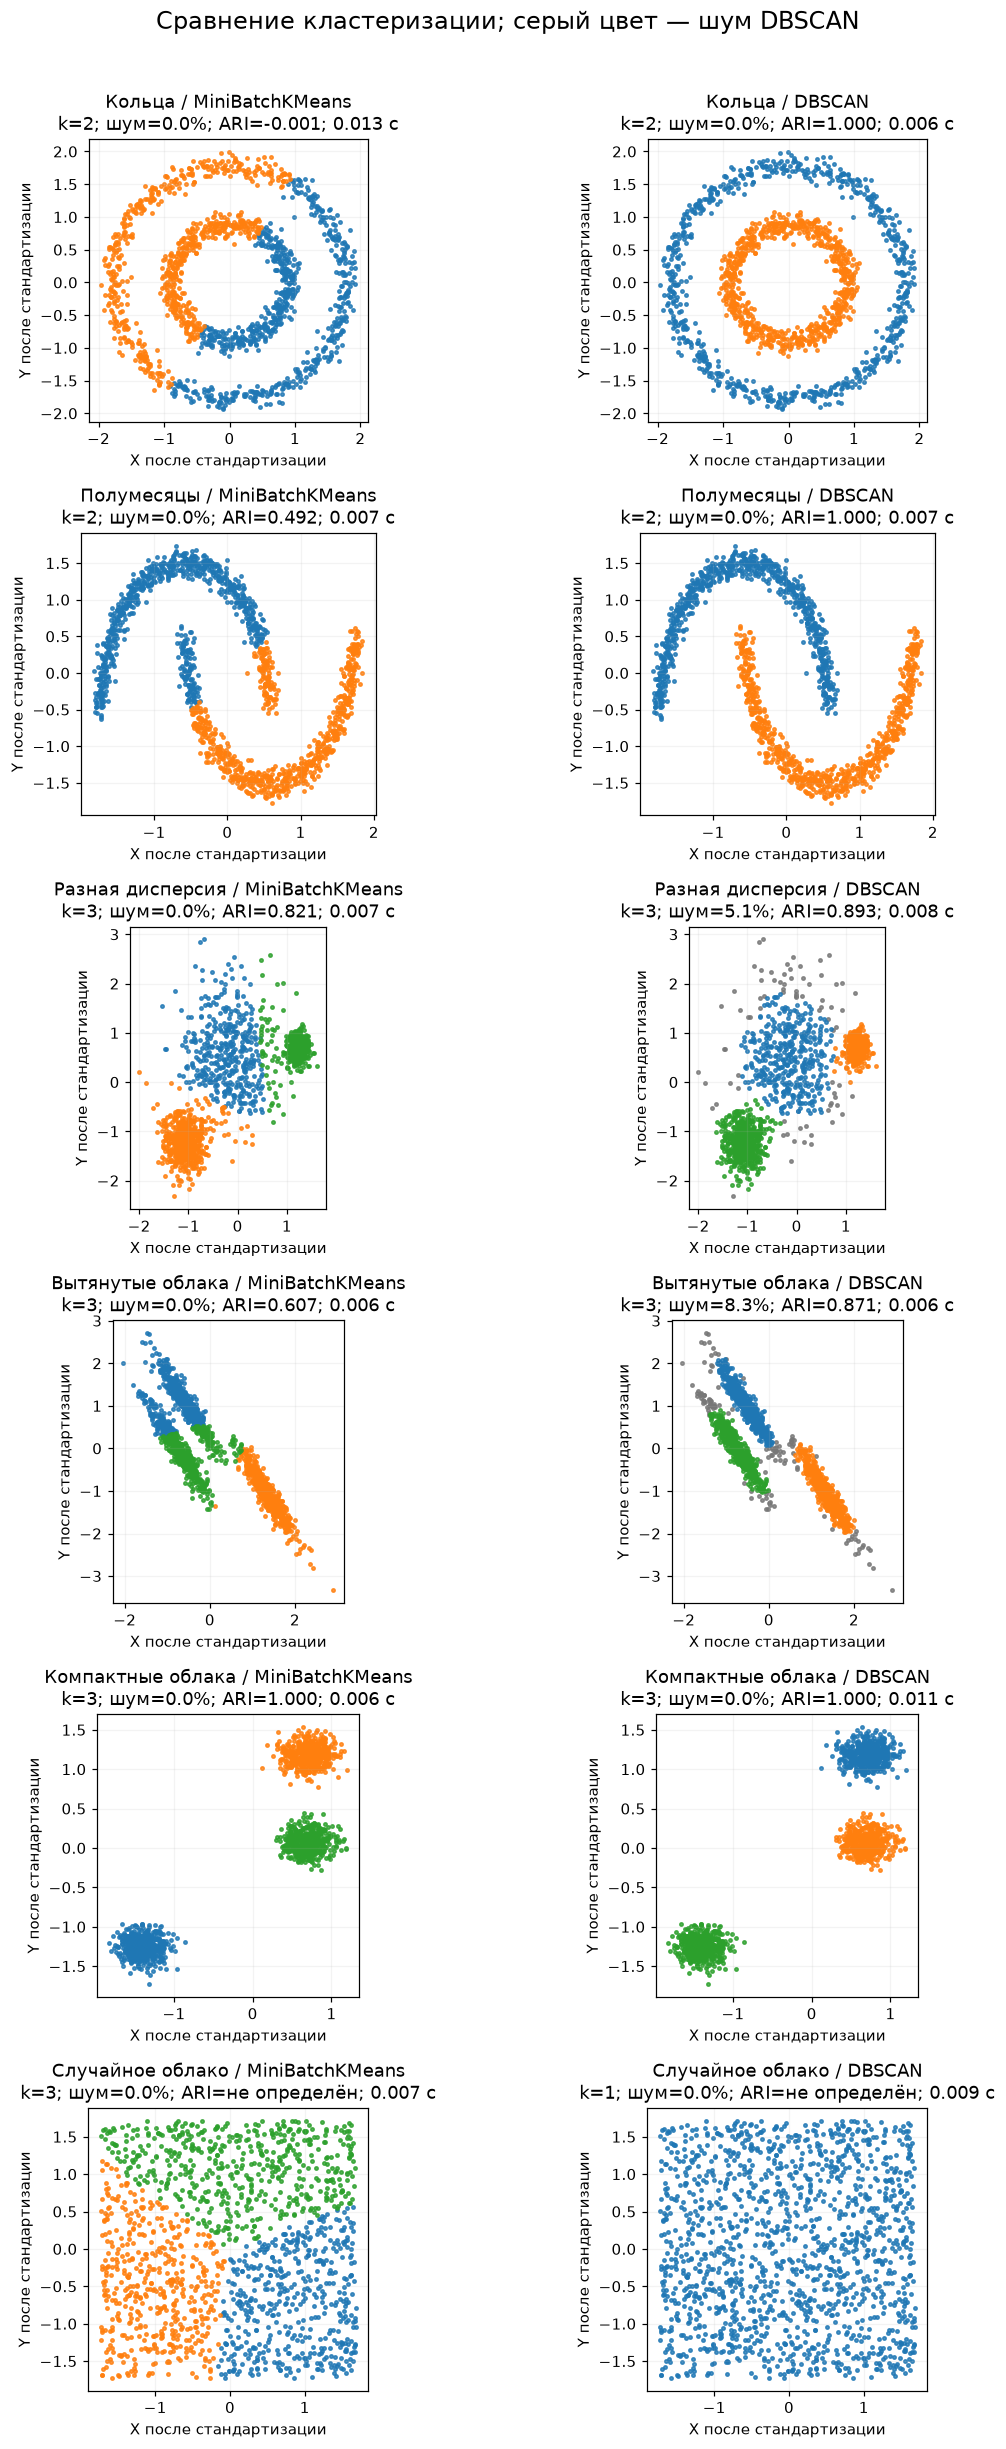

,Набор,Алгоритм,Кластеров,Доля шума,ARI,"Время, с"
0,Кольца,MiniBatchKMeans,2,0.000000,-0.000660,0.012717
1,Кольца,DBSCAN,2,0.000000,1.000000,0.006082
2,Полумесяцы,MiniBatchKMeans,2,0.000000,0.491529,0.006834
3,Полумесяцы,DBSCAN,2,0.000000,1.000000,0.006669
4,Разная дисперсия,MiniBatchKMeans,3,0.000000,0.821105,0.007033
5,Разная дисперсия,DBSCAN,3,0.051333,0.893472,0.007756
6,Вытянутые облака,MiniBatchKMeans,3,0.000000,0.607052,0.006463
7,Вытянутые облака,DBSCAN,3,0.083333,0.870977,0.005635
8,Компактные облака,MiniBatchKMeans,3,0.000000,1.000000,0.005978
9,Компактные облака,DBSCAN,3,0.000000,1.000000,0.010812


In [9]:
fig, axes = plt.subplots(len(benchmark_cases), 2, figsize=(11, 22), squeeze=False)
benchmark_rows = []
benchmark_labels = {}
for row, (dataset_name, (raw_X, y_true), params) in enumerate(benchmark_cases):
    X = StandardScaler().fit_transform(raw_X)
    # Новые экземпляры на каждом наборе используют параметры именно этого набора.
    two_means = cluster.MiniBatchKMeans(
        n_clusters=params["n_clusters"], random_state=0, n_init=10, batch_size=256)
    dbscan = cluster.DBSCAN(eps=params["eps"], min_samples=params["min_samples"])
    clustering_algorithms = (("MiniBatchKMeans", two_means), ("DBSCAN", dbscan))

    for col, (algorithm_name, algorithm) in enumerate(clustering_algorithms):
        t0 = time.perf_counter()
        labels = algorithm.fit_predict(X)
        elapsed = time.perf_counter() - t0
        benchmark_labels[dataset_name, algorithm_name] = labels
        n_clusters = len(set(labels) - {-1})
        noise_fraction = float(np.mean(labels == -1))
        ari = (float(adjusted_rand_score(y_true, labels))
               if y_true is not None else np.nan)
        benchmark_rows.append({
            "Набор": dataset_name, "Алгоритм": algorithm_name,
            "Кластеров": n_clusters, "Доля шума": noise_fraction,
            "ARI": ari, "Время, с": elapsed
        })
        ax = axes[row, col]
        for label in sorted(set(labels)):
            mask = labels == label
            color = "#777777" if label == -1 else plt.get_cmap("tab10")(int(label) % 10)
            ax.scatter(X[mask, 0], X[mask, 1], s=5, color=color, alpha=0.8)
        ari_text = "не определён" if np.isnan(ari) else f"{ari:.3f}"
        ax.set_title(f"{dataset_name} / {algorithm_name}\n"
                     f"k={n_clusters}; шум={noise_fraction:.1%}; ARI={ari_text}; {elapsed:.3f} с")
        ax.set(xlabel="X после стандартизации", ylabel="Y после стандартизации")
        ax.set_aspect("equal", adjustable="box")
        ax.grid(alpha=0.15)

fig.suptitle("Сравнение кластеризации; серый цвет — шум DBSCAN", fontsize=16, y=1.01)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "sklearn_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
benchmark_results = pd.DataFrame(benchmark_rows)
display(benchmark_results)
benchmark_results.to_csv(RESULTS_DIR / "sklearn_comparison.csv", index=False)
assert len(benchmark_results) == 12
assert benchmark_results["Время, с"].ge(0).all()

### Выводы

* **Кольца и полумесяцы.** DBSCAN восстанавливает две группы сложной формы.
  MiniBatchKMeans разбивает пространство на области вокруг центров,
  поэтому разрезает кольца и ошибается на изгибах полумесяцев.
* **Разная дисперсия.** Единый радиус DBSCAN сложнее согласовать с разной
  плотностью: часть разреженного облака оказывается шумом. KMeans назначает
  кластер каждой точке, но также ошибается около границ облаков.
* **Вытянутые облака.** DBSCAN следует вытянутой форме групп и отмечает
  часть крайних точек шумом. KMeans хуже описывает эту геометрию.
* **Компактные облака.** Оба алгоритма восстанавливают три хорошо разделённых
  кластера и получают ARI = 1.
* **Случайное облако.** KMeans выделяет три группы, поскольку это задано
  параметром. DBSCAN соединяет точки в одну плотную область. Оснований
  считать какое-либо из этих разбиений истинным здесь нет; ARI не вычисляется.

Для компактных групп удобен KMeans; при сложной форме и наличии шума полезен
DBSCAN. Его результат сильно зависит от `eps` и `min_samples`, а число
кластеров определяется самими данными и выбранными параметрами.